# 03 - Análise de Regressão

Objetivo: Prever `max_heart_rate_achieved` (Frequência Cardíaca Máxima Alcançada)

Este é um problema de **regressão** - prever um valor numérico contínuo.

## Importar bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## Carregar dados

In [2]:
df = pd.read_csv('../data/processed/dataset_regression.csv')
print(f"Dataset para regressão: {df.shape}")
print(f"\nPrimeiras linhas:")
print(df.head())

Dataset para regressão: (9000, 32)

Primeiras linhas:
   patient_id  age  sex  resting_bp_systolic  resting_bp_diastolic  \
0           1   44    1                  117                    74   
1           2   57    1                  139                    94   
2           3   29    1                  128                    78   
3           4   72    1                  132                    86   
4           5   62    0                  116                    75   

   cholesterol_total  hdl  ldl  triglycerides  fasting_blood_sugar  ...  \
0                193   57  106            119                  112  ...   
1                185   69  110             35                  114  ...   
2                197   52  108            157                   95  ...   
3                197   59  104            143                   92  ...   
4                154   65   75            104                  135  ...   

   daily_steps  diet_quality_score  has_heart_disease  \
0         7731   

## 1. Análise da Variável Alvo (Target)

In [3]:
target = 'max_heart_rate_achieved'

print(f"\n=== ANÁLISE DO TARGET: {target} ===")
print(f"\nEstatísticas:")
print(df[target].describe())

print(f"\nCaracterísticas:")
print(f"  Valores únicos: {df[target].nunique()}")
print(f"  Valores ausentes: {df[target].isnull().sum()}")
print(f"  Min: {df[target].min()}")
print(f"  Max: {df[target].max()}")
print(f"  Desvio padrão: {df[target].std():.2f}")


=== ANÁLISE DO TARGET: max_heart_rate_achieved ===

Estatísticas:
count    9000.000000
mean      164.838333
std        21.290773
min        93.000000
25%       150.000000
50%       166.000000
75%       180.000000
max       210.000000
Name: max_heart_rate_achieved, dtype: float64

Características:
  Valores únicos: 115
  Valores ausentes: 0
  Min: 93
  Max: 210
  Desvio padrão: 21.29


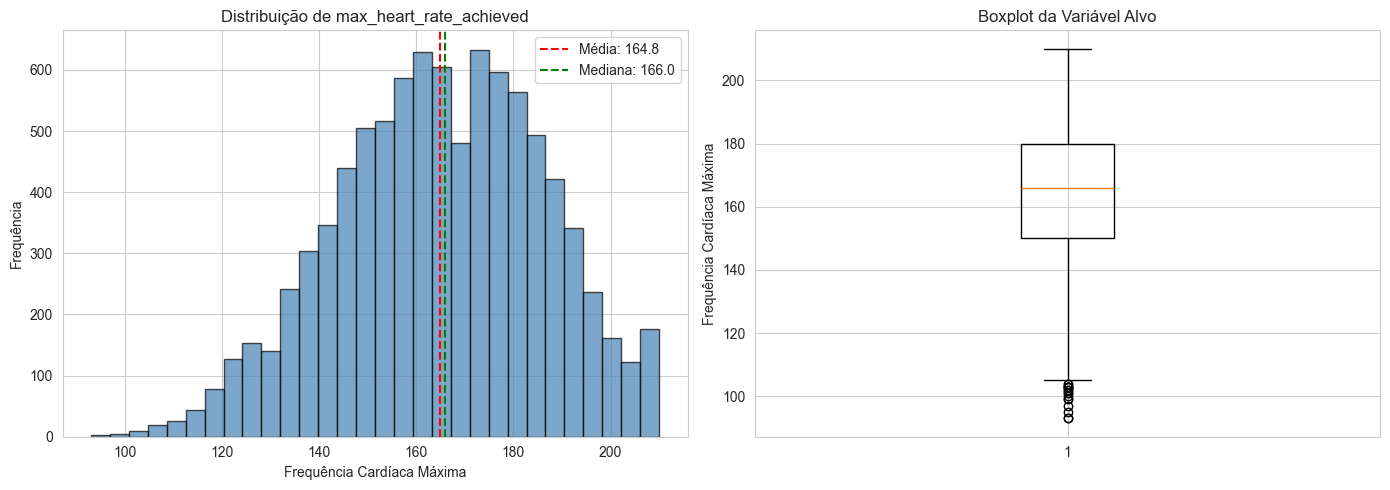

In [4]:
# Visualizar distribuição da variável alvo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma
axes[0].hist(df[target], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Frequência Cardíaca Máxima')
axes[0].set_ylabel('Frequência')
axes[0].set_title(f'Distribuição de {target}')
axes[0].axvline(df[target].mean(), color='red', linestyle='--', label=f'Média: {df[target].mean():.1f}')
axes[0].axvline(df[target].median(), color='green', linestyle='--', label=f'Mediana: {df[target].median():.1f}')
axes[0].legend()

# Boxplot
axes[1].boxplot(df[target])
axes[1].set_ylabel('Frequência Cardíaca Máxima')
axes[1].set_title('Boxplot da Variável Alvo')

plt.tight_layout()
plt.show()

## 2. Análise de Correlação com Features

In [5]:
# Calcular correlação com o target
correlacoes = df.corr()[target].sort_values(ascending=False)

print(f"\nCorrelação de cada feature com {target}:")
print("\n(Quanto mais próximo de 1 ou -1, mais forte a relação)\n")
print(correlacoes)


Correlação de cada feature com max_heart_rate_achieved:

(Quanto mais próximo de 1 ou -1, mais forte a relação)

max_heart_rate_achieved        1.000000
exercise_minutes_per_week      0.294445
daily_steps                    0.207887
hdl                            0.145244
diet_quality_score             0.090322
wearable_owner                 0.072071
smoker_Never                   0.044932
chest_pain_Asymptomatic        0.035533
sleep_hours                    0.023679
chest_pain_Non-Anginal Pain    0.013546
patient_id                    -0.004188
smoker_Former                 -0.004964
alcohol_units_per_week        -0.006069
chest_pain_Atypical Angina    -0.015067
family_history                -0.021002
sex                           -0.043889
triglycerides                 -0.051328
smoker_Current                -0.053016
chest_pain_Typical Angina     -0.056147
stress_score                  -0.076187
bmi                           -0.122960
resting_heart_rate            -0.124285
choles

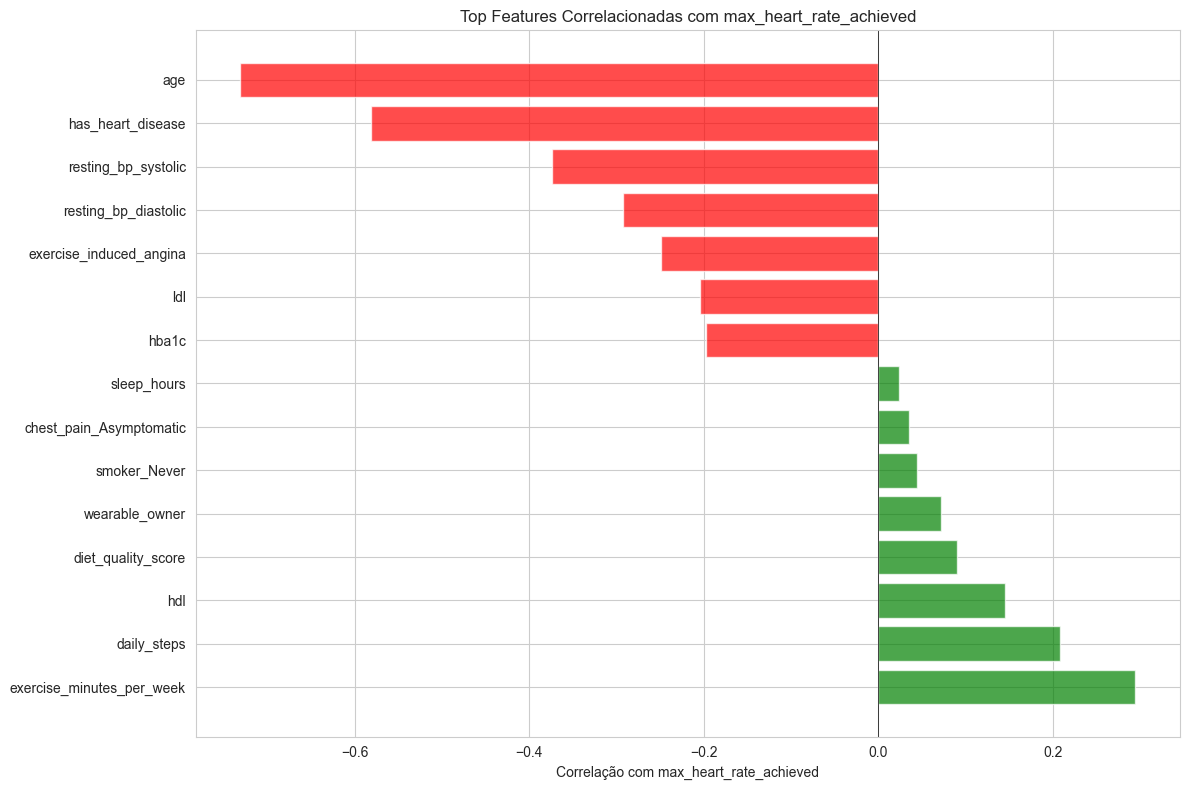

In [6]:
# Visualizar top correlações
fig, ax = plt.subplots(figsize=(12, 8))

# Remover o target dele mesmo
corr_target = correlacoes[correlacoes.index != target]

# Pegar top 15
top_corr = pd.concat([corr_target.head(8), corr_target.tail(7)])

colores = ['green' if x > 0 else 'red' for x in top_corr.values]
ax.barh(range(len(top_corr)), top_corr.values, color=colores, alpha=0.7)
ax.set_yticks(range(len(top_corr)))
ax.set_yticklabels(top_corr.index)
ax.set_xlabel(f'Correlação com {target}')
ax.set_title(f'Top Features Correlacionadas com {target}')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

## 3. Relação entre Features e Target

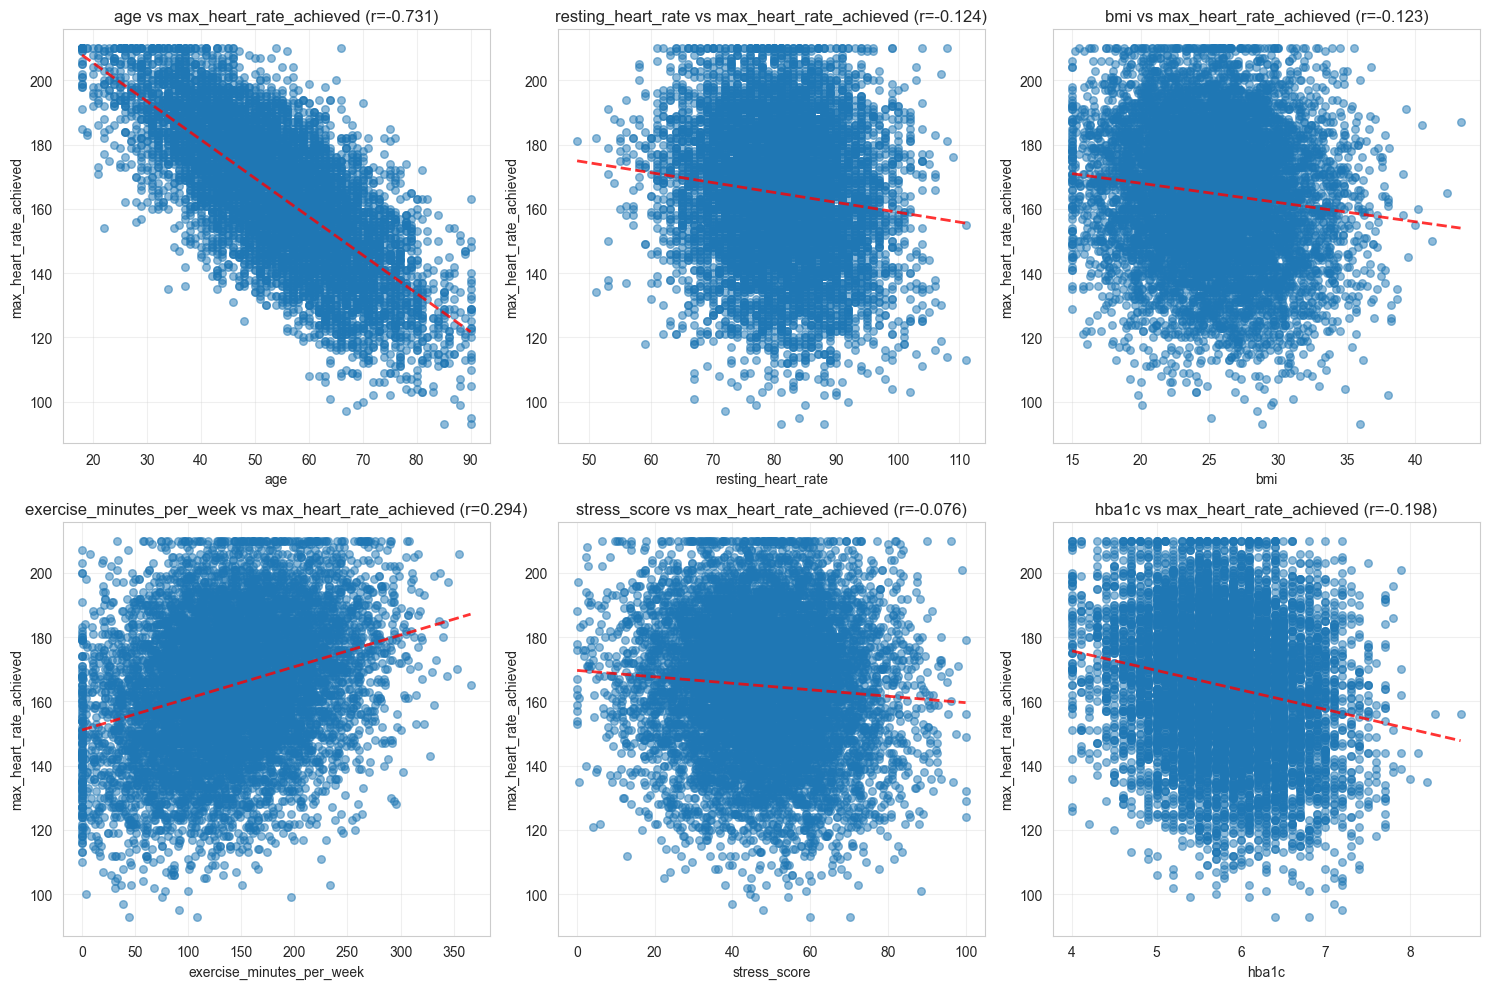

In [7]:
# Scatter plots das principais features vs target
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

top_features = ['age', 'resting_heart_rate', 'bmi', 'exercise_minutes_per_week', 'stress_score', 'hba1c']

for idx, feature in enumerate(top_features):
    axes[idx].scatter(df[feature], df[target], alpha=0.5, s=30)
    
    # Adicionar linha de tendência
    z = np.polyfit(df[feature], df[target], 1)
    p = np.poly1d(z)
    axes[idx].plot(df[feature].sort_values(), p(df[feature].sort_values()), "r--", alpha=0.8, linewidth=2)
    
    corr = df[feature].corr(df[target])
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel(target)
    axes[idx].set_title(f'{feature} vs {target} (r={corr:.3f})')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Justificativa da Escolha da Variável Alvo

In [8]:
print("="*70)
print(f"JUSTIFICATIVA: Por que {target} é uma boa variável para REGRESSÃO")
print("="*70)

print(f"""
✓ VARIABILIDADE: 
  - Mínimo: {df[target].min():.1f}
  - Máximo: {df[target].max():.1f}
  - Desvio padrão: {df[target].std():.2f}
  → Tem variação suficiente para modelagem

✓ RELEVÂNCIA CLÍNICA:
  - Frequência cardíaca máxima indica capacidade cardiovascular
  - Pacientes com doença cardíaca frequentemente têm FC máxima mais baixa
  - É um indicador importante de saúde cardíaca

✓ CORRELAÇÕES:
  - Correlação positiva com: {', '.join(correlacoes[1:4].index.tolist())}
  - Correlação negativa com: {', '.join(correlacoes[-3:].index.tolist())}
  - Múltiplas correlações significativas indicam relação com outras variáveis

✓ UTILIDADE PRÁTICA:
  - Prever FC máxima ajuda a avaliar capacidade de exercício
  - Importante para prescrição de atividades físicas seguras
  - Permite identificar pacientes com redução de capacidade
""")

JUSTIFICATIVA: Por que max_heart_rate_achieved é uma boa variável para REGRESSÃO

✓ VARIABILIDADE: 
  - Mínimo: 93.0
  - Máximo: 210.0
  - Desvio padrão: 21.29
  → Tem variação suficiente para modelagem

✓ RELEVÂNCIA CLÍNICA:
  - Frequência cardíaca máxima indica capacidade cardiovascular
  - Pacientes com doença cardíaca frequentemente têm FC máxima mais baixa
  - É um indicador importante de saúde cardíaca

✓ CORRELAÇÕES:
  - Correlação positiva com: exercise_minutes_per_week, daily_steps, hdl
  - Correlação negativa com: resting_bp_systolic, has_heart_disease, age
  - Múltiplas correlações significativas indicam relação com outras variáveis

✓ UTILIDADE PRÁTICA:
  - Prever FC máxima ajuda a avaliar capacidade de exercício
  - Importante para prescrição de atividades físicas seguras
  - Permite identificar pacientes com redução de capacidade



## 5. Verificação de Pressupostos de Regressão Linear

In [9]:
# Teste de normalidade dos resíduos
from scipy.stats import shapiro, normaltest

print("\nTeste de Normalidade do Target:")
stat_shapiro, p_shapiro = shapiro(df[target])
print(f"Shapiro-Wilk test: statistic={stat_shapiro:.4f}, p-value={p_shapiro:.4f}")
if p_shapiro > 0.05:
    print("✓ Target aproximadamente normal (p > 0.05)")
else:
    print("✗ Target não é normal (p <= 0.05) - pode precisar transformação")


Teste de Normalidade do Target:
Shapiro-Wilk test: statistic=0.9938, p-value=0.0000
✗ Target não é normal (p <= 0.05) - pode precisar transformação


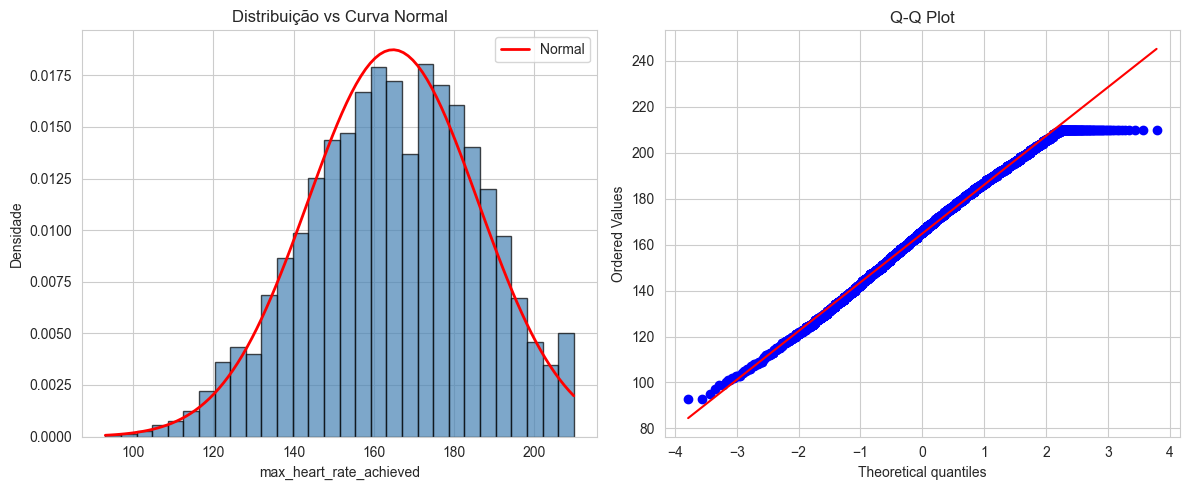

In [10]:
# Q-Q plot para visualizar normalidade
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histograma com curva normal
axes[0].hist(df[target], bins=30, density=True, alpha=0.7, color='steelblue', edgecolor='black')
mu, sigma = df[target].mean(), df[target].std()
x = np.linspace(df[target].min(), df[target].max(), 100)
axes[0].plot(x, stats.norm.pdf(x, mu, sigma), 'r-', linewidth=2, label='Normal')
axes[0].set_xlabel(target)
axes[0].set_ylabel('Densidade')
axes[0].set_title('Distribuição vs Curva Normal')
axes[0].legend()

# Q-Q plot
stats.probplot(df[target], dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

## 6. Recomendações para Modelagem

In [11]:
print("\n" + "="*70)
print("RECOMENDAÇÕES PARA MODELAGEM DE REGRESSÃO")
print("="*70)

print("""
📊 CARACTERÍSTICAS DO PROBLEMA:
  - Tipo: Regressão (prever valor contínuo)
  - Target: max_heart_rate_achieved
  - Número de samples: {} 
  - Número de features: {}

🎯 PRINCIPAIS FEATURES RECOMENDADAS:
  1. age (idade) - Correlação: {:.3f}
  2. resting_heart_rate (FC repouso) - Correlação: {:.3f}
  3. bmi (IMC) - Correlação: {:.3f}
  4. exercise_minutes_per_week (exercício semanal) - Correlação: {:.3f}
  5. stress_score (estresse) - Correlação: {:.3f}

⚠️ POSSÍVEIS DESAFIOS:
  • Relação não-linear entre algumas features e target
  • Multicolinearidade entre age e outras variáveis
  • Heterocedasticidade possível em grupos de idade extremos

🤖 ALGORITMOS RECOMENDADOS PARA TESTAR:
  
  SIMPLES (bom para começar):
  ✓ Regressão Linear Simples
  ✓ Regressão de Ridge
  ✓ Regressão de Lasso
  
  INTERMEDIÁRIO (melhor desempenho):
  ✓ K-Nearest Neighbors (KNN) - sem padronização é ruim
  ✓ Decision Trees
  ✓ Random Forest (pode capturar não-linearidade)
  
  AVANÇADO (validação cruzada necessária):
  ✓ Support Vector Regression (SVR)
  ✓ Gradient Boosting (XGBoost, LightGBM)

💡 DICAS:
  • Usar dados padronizados para KNN e SVR
  • Decision Trees e Random Forest não precisam padronização
  • Testar com validação cruzada para melhor avaliação
  • Usar métricas: MAE, MSE, RMSE, R² score
""".format(
    len(df),
    len(df.columns) - 1,  # -1 para excluir patient_id
    correlacoes['age'],
    correlacoes['resting_heart_rate'],
    correlacoes['bmi'],
    correlacoes['exercise_minutes_per_week'],
    correlacoes['stress_score']
))


RECOMENDAÇÕES PARA MODELAGEM DE REGRESSÃO

📊 CARACTERÍSTICAS DO PROBLEMA:
  - Tipo: Regressão (prever valor contínuo)
  - Target: max_heart_rate_achieved
  - Número de samples: 9000 
  - Número de features: 31

🎯 PRINCIPAIS FEATURES RECOMENDADAS:
  1. age (idade) - Correlação: -0.731
  2. resting_heart_rate (FC repouso) - Correlação: -0.124
  3. bmi (IMC) - Correlação: -0.123
  4. exercise_minutes_per_week (exercício semanal) - Correlação: 0.294
  5. stress_score (estresse) - Correlação: -0.076

⚠️ POSSÍVEIS DESAFIOS:
  • Relação não-linear entre algumas features e target
  • Multicolinearidade entre age e outras variáveis
  • Heterocedasticidade possível em grupos de idade extremos

🤖 ALGORITMOS RECOMENDADOS PARA TESTAR:

  SIMPLES (bom para começar):
  ✓ Regressão Linear Simples
  ✓ Regressão de Ridge
  ✓ Regressão de Lasso

  INTERMEDIÁRIO (melhor desempenho):
  ✓ K-Nearest Neighbors (KNN) - sem padronização é ruim
  ✓ Decision Trees
  ✓ Random Forest (pode capturar não-linearidade